## Pronóstico de la demanda de servicios de transporte

### Descripción del proyecto

Sweet Lift Taxi es una empresa de servicios de transporte que necesita anticipar la demanda de taxis en los aeropuertos para mejorar la disponibilidad de conductores durante las horas de mayor afluencia.

La empresa ha recopilado datos históricos sobre las solicitudes de taxis y desea predecir el número de pedidos para la hora siguiente. Un pronóstico preciso de la demanda puede ayudar a optimizar la asignación de conductores, reducir los tiempos de espera de los pasajeros y favorecer una planificación operativa más eficiente.

## Preparación

In [16]:
# Importar librerías necesarias
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import mean_squared_error

## Carga de datos

In [17]:
# Descargamos datos y los remuestreamos a una hora
data = pd.read_csv('../data/taxi.csv', index_col=[0], parse_dates=[0])

data.sort_index(inplace=True)
data = data.resample('1H').sum()

data.head()

C:\Users\Particular\AppData\Local\Temp\ipykernel_12564\2022029597.py:5: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  data = data.resample('1H').sum()


,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


## EDA

In [18]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4416 entries, 2018-03-01 00:00:00 to 2018-08-31 23:00:00
Freq: h
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  4416 non-null   int64
dtypes: int64(1)
memory usage: 69.0 KB


### Hourly Taxi Demand

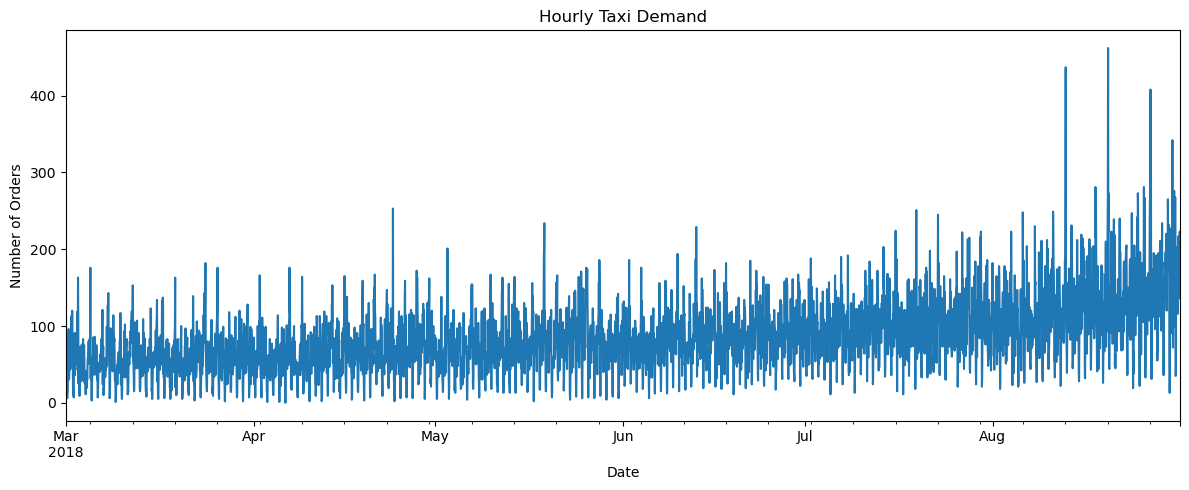

In [19]:
plt.figure(figsize=(12, 5))
data['num_orders'].plot()

plt.title('Hourly Taxi Demand')
plt.xlabel('Date')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()


In [20]:
data.describe()

,num_orders
count,4416.000000
mean,84.422781
std,45.023853
min,0.000000
25%,54.000000
50%,78.000000
75%,107.000000
max,462.000000


### Principales hallazgos

El conjunto de datos contiene 4.416 observaciones horarias correspondientes al periodo de marzo a agosto de 2018, sin valores faltantes.

La demanda de taxis registra un promedio de aproximadamente 84 solicitudes por hora, con una variabilidad considerable. La serie temporal muestra una tendencia ascendente, patrones recurrentes y picos de demanda ocasionales.

Estos resultados sugieren que la demanda histórica y las características temporales podrían servir para predecir la demanda futura de taxis y facilitar una asignación más eficiente de los conductores.

## Ingeniería de características

In [21]:
def make_features(data, max_lag, rolling_mean_size):

    data = data.copy()

    data['hour'] = data.index.hour
    data['dayofweek'] = data.index.dayofweek
    data['month'] = data.index.month

    for lag in range(1, max_lag + 1):
        data[f'lag_{lag}'] = data['num_orders'].shift(lag)

    data['rolling_mean'] = (data['num_orders'].shift().rolling(rolling_mean_size).mean())

    return data

data_features = make_features(data, max_lag=24, rolling_mean_size=24)

data_features.dropna(inplace=True)

In [22]:
# Comprobamos nuevas columnas
data_features.shape

(4392, 29)

### Resumen de la ingeniería de características

Se crearon variables basadas en el tiempo, variables de rezago (lag) a 24 horas y una media móvil de 24 horas para capturar los patrones históricos de la demanda.

La media móvil utiliza únicamente observaciones previas para evitar la fuga de datos (data leakage). Se eliminaron las filas con valores faltantes resultantes de los cálculos de rezago y de media móvil.

In [23]:
# Separate features and target
X = data_features.drop('num_orders', axis=1)
y = data_features['num_orders']

# Chronological train, validation, and test split
n = len(X)
train_end = int(n * 0.8)
val_end = int(n * 0.9)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (3513, 28)
Validation: (439, 28)
Test: (440, 28)


In [24]:
# Crear función RMSE
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


## Entrenar modelo Linear Regression

In [25]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_val)
lr_rmse = rmse(y_val, lr_pred)

print(f"Linear Regression Validation RMSE: {lr_rmse:.2f}")

Linear Regression Validation RMSE: 34.22


### Random Forest

In [26]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_val)
rf_rmse = rmse(y_val, rf_pred)

print(f"Random Forest Validation RMSE: {rf_rmse:.2f}")

Random Forest Validation RMSE: 32.58


### CatBoost

In [27]:
cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    random_seed=42,
    verbose=False
)

cat_model.fit(X_train, y_train)

cat_pred = cat_model.predict(X_val)
cat_rmse = rmse(y_val, cat_pred)

print(f"CatBoost Validation RMSE: {cat_rmse:.2f}")

CatBoost Validation RMSE: 31.02


### LightGBM

In [28]:
lgbm_model = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)

lgbm_pred = lgbm_model.predict(X_val)
lgbm_rmse = rmse(y_val, lgbm_pred)

print(f"LightGBM Validation RMSE: {lgbm_rmse:.2f}")

LightGBM Validation RMSE: 31.75


## Comparación de modelos

In [29]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'CatBoost', 'LightGBM'],
    'Validation RMSE': [lr_rmse, rf_rmse, cat_rmse, lgbm_rmse]
})

results.sort_values('Validation RMSE')

,Model,Validation RMSE
2,CatBoost,31.021668
3,LightGBM,31.746895
1,Random Forest,32.578057
0,Linear Regression,34.220434


### Selección de modelo

CatBoost obtuvo el RMSE de validación más bajo (31,02), superando a la Regresión Lineal, Random Forest y LightGBM.

A partir de estos resultados, se seleccionó CatBoost para la evaluación final en el conjunto de prueba reservado.

## Evaluación de Modelo Final

In [30]:
# Retrain the selected model using training and validation data
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

final_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    random_seed=42,
    verbose=False
)

final_model.fit(X_train_final, y_train_final)

# Final evaluation on unseen test data
test_pred = final_model.predict(X_test)
test_rmse = rmse(y_test, test_pred)

print(f"Final Test RMSE: {test_rmse:.2f}")

Final Test RMSE: 41.33


### Actual vs. Predicted Demand

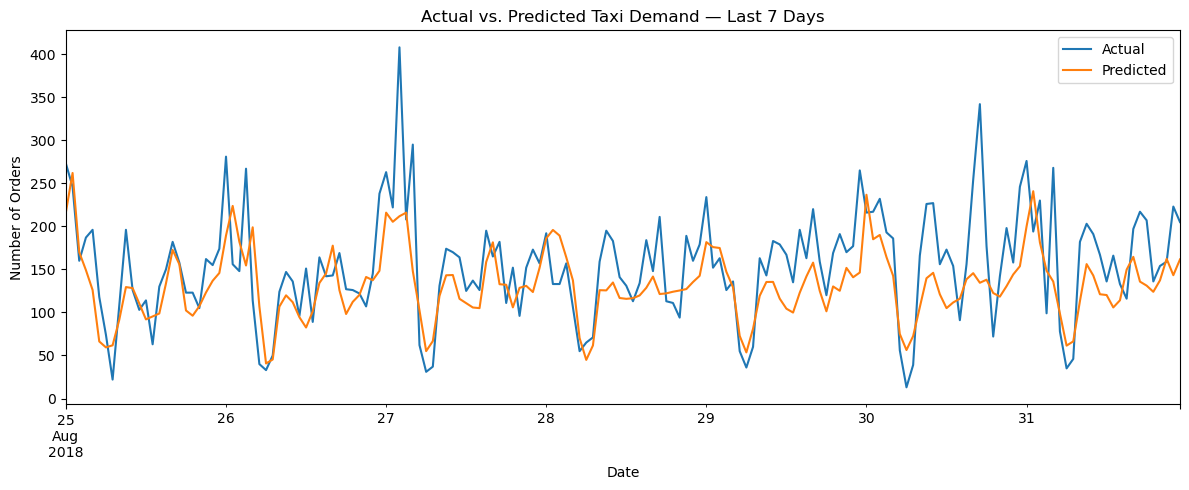

In [31]:
# Compare actual and predicted demand over the last 7 days
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': test_pred
}, index=y_test.index)

comparison.tail(168).plot(figsize=(12, 5))

plt.title('Actual vs. Predicted Taxi Demand — Last 7 Days')
plt.xlabel('Date')
plt.ylabel('Number of Orders')
plt.legend()
plt.tight_layout()
plt.show()

## Conclusiones y recomendaciones para el negocio

CatBoost obtuvo el mejor rendimiento en la validación (RMSE: 31,02) y un RMSE en la prueba final de 41,33, cumpliendo con el objetivo del proyecto de situarse en 48 o menos.

El modelo logra captar los patrones generales de demanda horaria, pero tiende a subestimar los picos repentinos de demanda, especialmente durante los periodos de mayor actividad.

### Recomendaciones para el negocio:

- Utilizar las previsiones de demanda horaria como apoyo para la asignación de conductores y la planificación operativa.
- Mantener una mayor disponibilidad de conductores durante los periodos en los que históricamente se registra una alta demanda, dado que el modelo podría subestimar los picos inesperados.
- Realizar un seguimiento de los errores de previsión y reentrenar el modelo periódicamente a medida que se disponga de nuevos datos sobre la demanda.

En conjunto, los resultados demuestran cómo la previsión de series temporales puede contribuir a la toma de decisiones operativas más fundamentadas en los servicios de transporte con conductor.